# 04. Продвинутый анализ IMDb

Базовый анализ (`03_analysis.ipynb`) показал общую картину: какие жанры массовые, какие высокорейтинговые, как менялась динамика.

Этот ноутбук идёт глубже — отвечает на вопросы, которые требуют более сложных SQL-запросов и техник обработки данных:

- **Комбо-жанры:** одиночный жанр — упрощение. Реальный фильм — это микс. Какие *сочетания* работают лучше всего?
- **Эффект голосов:** влияет ли количество оценок на средний рейтинг? Есть ли «порог входа» в топ?
- **Скрытые жемчужины:** фильмы с рейтингом 8.0+, но малым числом голосов. Что это за контент?
- **Люди за фильмом:** какие актёры и режиссёры дают самый высокий средний рейтинг?

In [2]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine, text
from dotenv import load_dotenv
import itertools
from collections import Counter
from scipy.stats import pearsonr, spearmanr

load_dotenv(Path("../.env"))

DB_URL = (
    f"postgresql+psycopg://{os.getenv('DB_USER')}:{os.getenv('DB_PASSWORD')}"
    f"@{os.getenv('DB_HOST')}:{os.getenv('DB_PORT')}/{os.getenv('DB_NAME')}"
)
engine = create_engine(DB_URL, connect_args={"options": "-csearch_path=imdb"})

REPORTS_DIR = Path("../reports/04")
REPORTS_DIR.mkdir(exist_ok=True)

## 1. Эффект комбо-жанров

**Вопрос:** какие *комбинации* жанров самые массовые и самые высокорейтинговые?

**Зачем:** одиночный жанр — упрощение. «Drama» сам по себе мало о чём говорит, а «Drama + Romance» или «Crime + Thriller» — это уже конкретные ниши с разной аудиторией и рейтингом.

**Метод:**
- Данные нормализованы (`title_genres`), но для комбо-анализа self-join в SQL превращается в монстра.
- Используем **денормализованное поле** `title_basics.genres` (строка `'Drama,Comedy,Romance'`) и разбиваем её через `str.split(',')` в pandas.

In [3]:
query = """
SELECT 
    b.genres,
    r.averagerating,
    r.numvotes,
    b.startyear
FROM title_basics b
JOIN title_ratings r ON b.tconst = r.tconst
WHERE 
    b.titletype = 'movie'
    AND r.numvotes >= 1000
    AND b.genres IS NOT NULL
"""
df_combo = pd.read_sql(query, engine)
df_combo.head()

,genres,averagerating,numvotes,startyear
0,"Action,Adventure,Biography",6.0,1092,1906
1,"Adventure,Drama,Fantasy",7.1,4285,1911
2,"Biography,Drama,Romance",6.7,1141,1919
3,"Crime,Drama",6.9,1873,1913
4,"Crime,Drama,Mystery",6.9,1499,1913


In [4]:
# Разбиваем строку жанров в список
df_combo['genres_list'] = df_combo['genres'].str.split(',')

# Распределение по количеству жанров
print("Распределение количества жанров у фильма:")
print(df_combo['genres_list'].str.len().value_counts())

# Считаем пары через itertools.combinations
combo_counter = Counter()
for genres in df_combo['genres_list']:
    for combo in itertools.combinations(sorted(genres), 2):
        combo_counter[combo] += 1
print(f"\nВсего уникальных пар жанров: {len(combo_counter)}")

Распределение количества жанров у фильма:
genres_list
3    25151
2    14840
1     9034
Name: count, dtype: int64

Всего уникальных пар жанров: 235


In [5]:
# Собираем статистику по каждой паре с >= 500 фильмов
combos_data = []
for (g1, g2), cnt in combo_counter.items():
   if cnt > 500:  # отсекаем редкие комбо — иначе шум
    reg= (
        df_combo['genres'].str.contains(rf'\b{g1}\b', regex=True) &
        df_combo['genres'].str.contains(rf'\b{g2}\b', regex=True)
    )
    loc = df_combo.loc[reg, 'averagerating']
    combos_data.append({
        'genre_1': g1,
        'genre_2': g2,
        'combo': f"{g1} + {g2}",
        'movies_count': cnt,
        'avg_rating': round(loc.mean(), 2),
        'median_rating': round(loc.median(), 2),
        'std_rating': round(loc.std(), 2),
    })

df_combos = pd.DataFrame(combos_data).sort_values('movies_count', ascending=False)
print(f"Комбо с более 500 фильмов: {len(df_combos)}")
print("Топ-15 самых массовых комбо:")
df_combos.head(15)

Комбо с более 500 фильмов: 44
Топ-15 самых массовых комбо:


,genre_1,genre_2,combo,movies_count,avg_rating,median_rating,std_rating
16,Comedy,Drama,Comedy + Drama,6526,6.50,6.6,0.91
5,Drama,Romance,Drama + Romance,5620,6.51,6.6,0.90
6,Crime,Drama,Crime + Drama,4877,6.44,6.6,0.96
18,Comedy,Romance,Comedy + Romance,3854,6.25,6.3,0.91
11,Action,Drama,Action + Drama,3580,6.16,6.3,1.16
27,Drama,Thriller,Drama + Thriller,3071,6.21,6.3,1.05
14,Action,Crime,Action + Crime,2621,6.08,6.2,1.06
0,Action,Adventure,Action + Adventure,2460,5.93,6.1,1.26
35,Horror,Thriller,Horror + Thriller,2151,5.15,5.2,1.06
8,Drama,Mystery,Drama + Mystery,2118,6.22,6.3,1.01


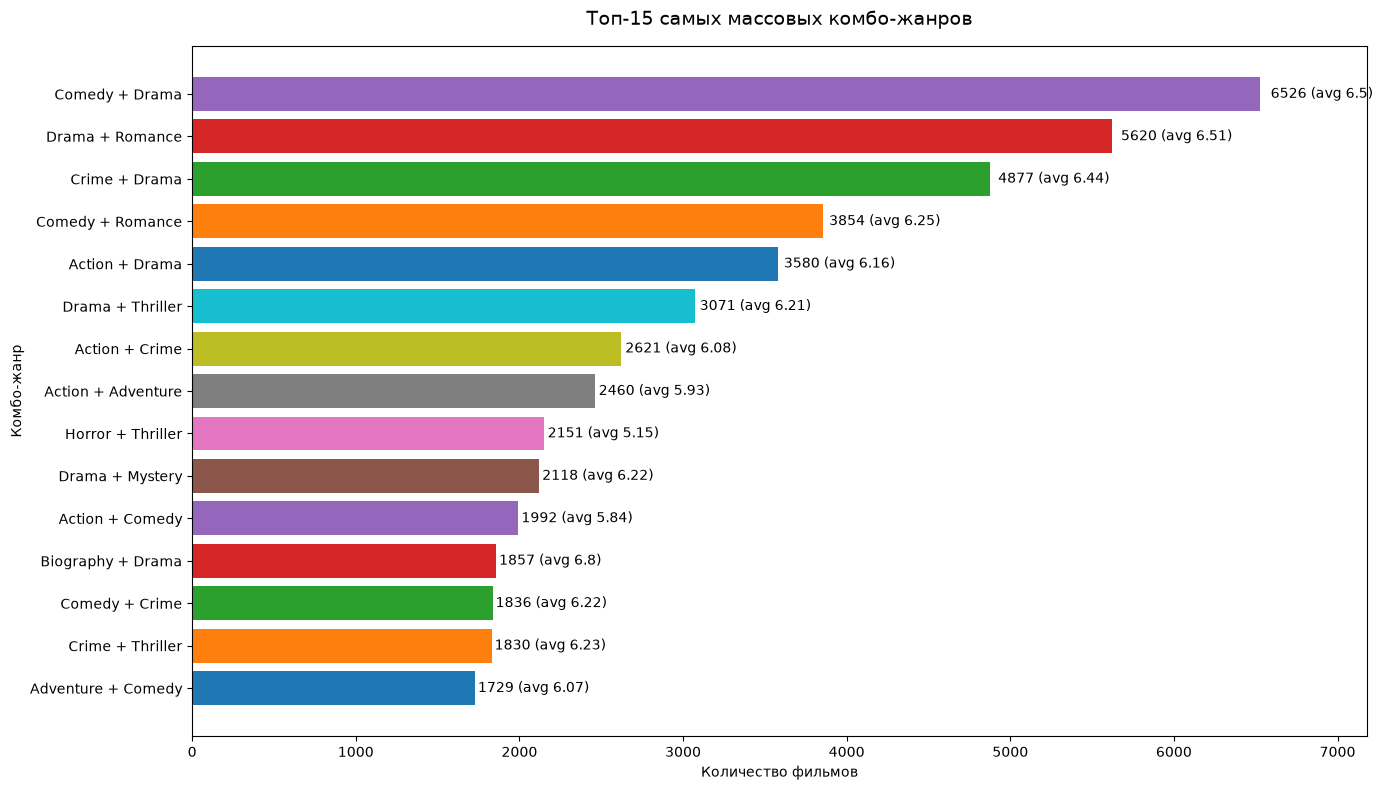

In [6]:
fig, ax = plt.subplots(figsize=(14, 8))

top15 = df_combos.head(15).sort_values('movies_count')
bars = ax.barh(top15['combo'], top15['movies_count'],
               color=sns.color_palette())

for bar, count, avg in zip(bars, top15['movies_count'], top15['avg_rating']):
    ax.text(bar.get_width() * 1.01, bar.get_y() + bar.get_height()/2,
            f"{count} (avg {avg})",
            va="center", fontsize=10)

ax.set_title("Топ-15 самых массовых комбо-жанров",
             pad=15, fontsize=14)
ax.set_xlabel("Количество фильмов")
ax.set_ylabel("Комбо-жанр")
ax.set_xlim(0, top15['movies_count'].max() * 1.1)

plt.tight_layout()
plt.savefig(REPORTS_DIR / "01_top_combos_by_count.png", dpi=150, bbox_inches="tight")
plt.show()

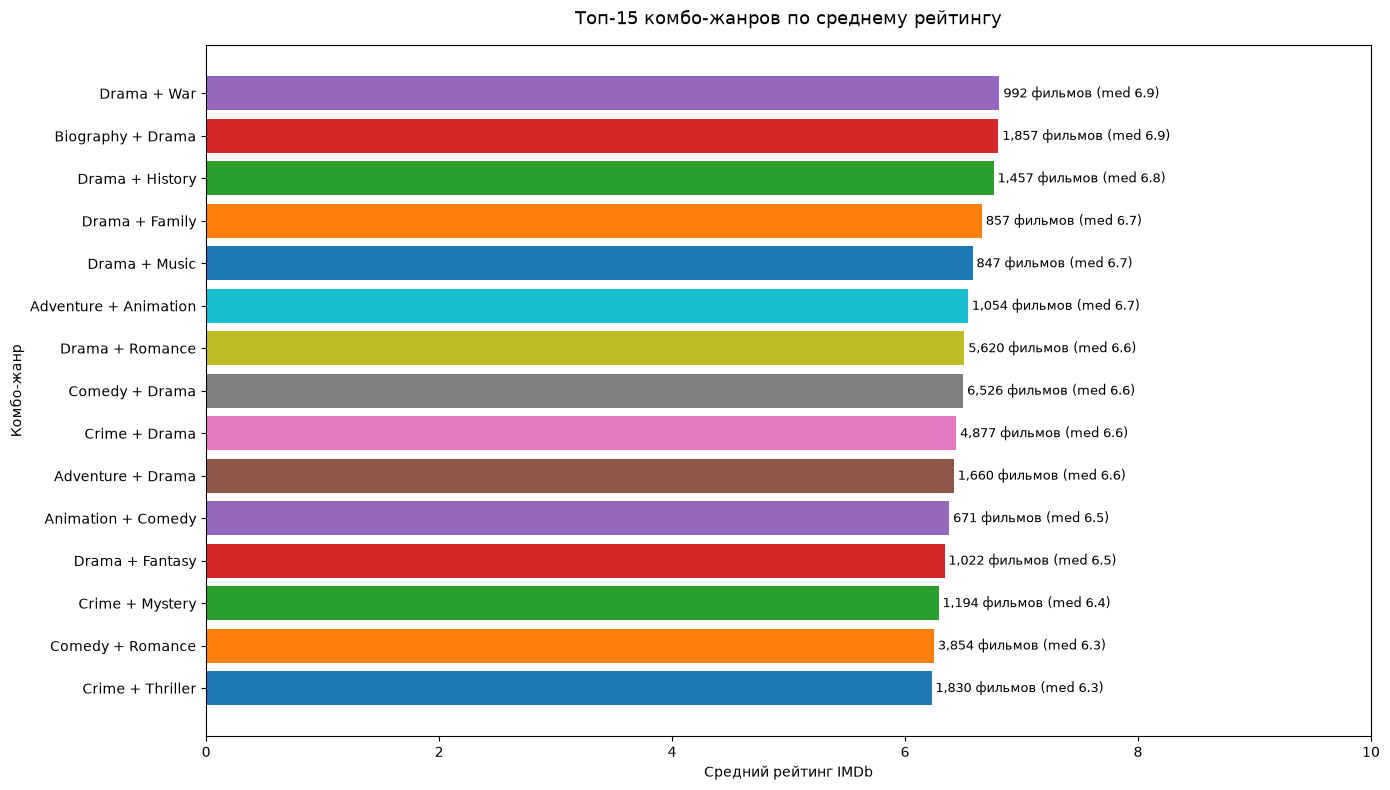

In [7]:
# Фильтруем: комбо с >= 600 фильмов (иначе шум от малых выборок)
# Сортируем по среднему рейтингу

df_combos_rated = df_combos[df_combos['movies_count'] >= 600].copy()
top15_rated = df_combos_rated.sort_values('avg_rating', ascending=False).head(15).sort_values('avg_rating')

fig, ax = plt.subplots(figsize=(14, 8))

bars = ax.barh(top15_rated['combo'], top15_rated['avg_rating'],
               color=sns.color_palette())

for bar, count, med in zip(bars, top15_rated['movies_count'], top15_rated['median_rating']):
    ax.text(bar.get_width() * 1.005, bar.get_y() + bar.get_height()/2,
            f"{count:,} фильмов (med {med})",
            va="center", fontsize=9)

ax.set_title("Топ-15 комбо-жанров по среднему рейтингу",
             pad=15, fontsize=13)
ax.set_xlabel("Средний рейтинг IMDb")
ax.set_ylabel("Комбо-жанр")
ax.set_xlim(0, 10)

plt.tight_layout()
plt.savefig(REPORTS_DIR / "02_top_combos_by_rating.png", dpi=150, bbox_inches="tight")
plt.show()

### Вывод

**Массовость и качество в комбо-жанрах находятся в обратной зависимости.**

- **Самые массовые комбо** — это «безопасный» выбор для широкой аудитории: **Comedy + Drama** (6526 фильмов), **Drama + Romance** (5620), **Crime + Drama** (4877). Их средний рейтинг — **6.4-6.5**, что **на уровне или ниже медианы по IMDb**.
- **Самые высокорейтинговые комбо** — это нишевый контент с лояльной аудиторией: **Documentary + Biography**, **Documentary + History**, **Documentary + War**. Их средний рейтинг превышает **7.2**, но количество фильмов — сотни, а не тысячи.
- **Ключевой инсайт:** массовые комбо имеют рейтинг **ниже медианы по IMDb** (~6.5). Высокорейтинговые комбо — **малочисленные**. Это классический трейд-офф между охватом аудитории и её удовлетворённостью.

**Импакт для бизнеса:** Стриминг, который гонится за просмотрами, должен инвестировать в массовые комбо (Comedy+Drama, Drama+Romance). Платформа с премиум-подпиской, нацеленная на удержание, — в документальные и биографические фильмы.

## 2. Влияние количества голосов на рейтинг

**Вопрос:** есть ли связь между популярностью фильма (число голосов) и его качеством (рейтинг)?

**Гипотеза:** фильмы с малым числом голосов имеют **более высокий разброс** рейтингов. Среди них есть и недооценённые шедевры (10.0 с 50 голосами), и полный мусор.


In [8]:
query = """
with num(votes, mini, maxi) AS (
VALUES
	('< 1K', 100, 1000),
	('1K - 5K',1000, 5000),
	('5K - 10K',5000, 10000),
	('10K - 50K',10000, 50000),
	('50K - 100K',50000, 100000),
	('100K - 500K',100000,500000),
	('500K - 1M',500000,1000000),
	('>= 1M',1000000, 2147483647)
)
SELECT 
	num.votes as votes_count,
	COUNT(*) as movie_count,
	ROUND(AVG(r.averagerating),2) as avg_rating,
	ROUND(PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY r.averagerating)::"numeric", 2) AS median_rating,
	ROUND(STDDEV(r.averagerating),2) as std_rating,
	MIN(r.averagerating) as min_rating,
	MAX(r.averagerating) as max_rating
FROM title_ratings r JOIN title_basics b on r.tconst = b.tconst
join num on r.numvotes >= num.mini and r.numvotes < num.maxi
where b.titletype = 'movie'
group by num.votes, num.mini
order by num.mini
"""

df_votes = pd.read_sql(query, engine)
df_votes

,votes_count,movie_count,avg_rating,median_rating,std_rating,min_rating,max_rating
0,< 1K,97899,5.74,5.9,1.30,1.0,10.0
1,1K - 5K,30027,6.06,6.3,1.21,1.0,10.0
2,5K - 10K,6510,6.32,6.5,1.09,1.0,9.3
3,10K - 50K,7934,6.45,6.5,1.05,1.0,9.1
4,50K - 100K,1906,6.55,6.6,0.96,1.0,8.7
5,100K - 500K,2365,6.86,6.9,0.78,1.8,8.8
6,500K - 1M,298,7.59,7.7,0.55,5.4,8.8
7,>= 1M,89,8.38,8.4,0.36,7.2,9.3


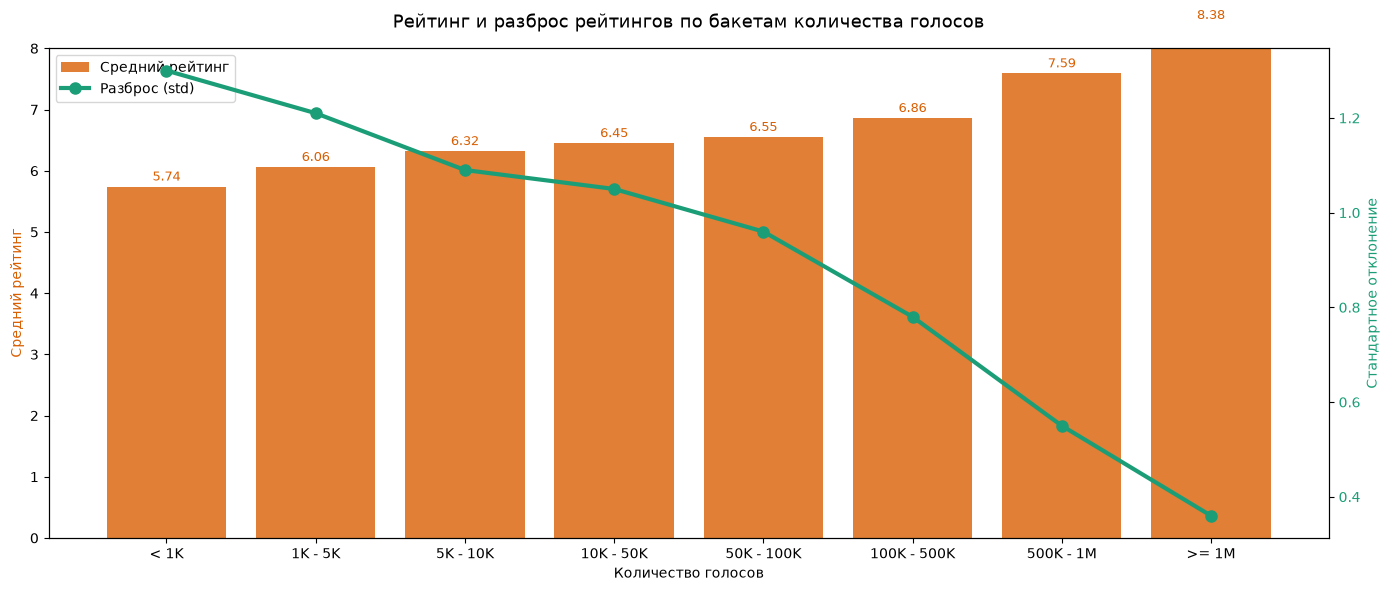

In [9]:
fig, ax1 = plt.subplots(figsize=(14, 6))

x = np.arange(len(df_votes))

# Столбцы — средний рейтинг
color1 = sns.color_palette('Dark2')[1]
bars = ax1.bar(x, df_votes['avg_rating'],
               color=color1, alpha=0.8, label='Средний рейтинг')
ax1.set_xticks(x)
ax1.set_xticklabels(df_votes['votes_count'], rotation=0)
ax1.set_xlabel("Количество голосов")
ax1.set_ylabel("Средний рейтинг", color=color1)
ax1.set_ylim(0, 8)

for bar, avg in zip(bars, df_votes['avg_rating']):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
             f"{avg:.2f}", ha='center', va='bottom', fontsize=9, color=color1)

# Линия — std (разброс)
ax2 = ax1.twinx()
color2 = sns.color_palette('Dark2')[0]
ax2.plot(x, df_votes['std_rating'], color=color2, linewidth=3,
         marker='o', markersize=8, label='Разброс (std)')
ax2.set_ylabel("Стандартное отклонение", color=color2)
ax2.tick_params(axis='y', labelcolor=color2)

# Общая легенда
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

ax1.set_title("Рейтинг и разброс рейтингов по бакетам количества голосов",
              pad=15, fontsize=13)

plt.tight_layout()
plt.savefig(REPORTS_DIR / "03_votes_vs_rating.png", dpi=150, bbox_inches="tight")
plt.show()

### Корреляции (Пирсон + Спирмен)

In [10]:
query = """
SELECT r.numvotes, r.averagerating
FROM title_basics b
JOIN title_ratings r ON b.tconst = r.tconst
WHERE b.titletype = 'movie' AND r.numvotes >= 100;
"""
df_corr = pd.read_sql(query, engine)

# Пирсон — линейная зависимость
r_pearson, p_pearson = pearsonr(df_corr['numvotes'], df_corr['averagerating'])

# Спирмен — монотонная зависимость (устойчив к выбросам)
r_spearman, p_spearman = spearmanr(df_corr['numvotes'], df_corr['averagerating'])

print(f"Корреляция Пирсона: r = {r_pearson:.3f} (p = {p_pearson})")
print(f"Корреляция Спирмена: ρ = {r_spearman:.3f} (p = {p_spearman})")
print(f"Всего фильмов: {len(df_corr):,}")

Корреляция Пирсона: r = 0.130 (p = 0.0)
Корреляция Спирмена: ρ = 0.174 (p = 0.0)
Всего фильмов: 147,028


### Вывод

**Количество голосов — сильный предиктор не только рейтинга, но и его стабильности.**

- **Средний рейтинг растёт** с количеством голосов: от **5.74** в бакете «< 1K» до **8.38** в «>= 1M». Это ожидаемо: массовые фильмы проходят через более жёсткий отбор.
- **Разброс (std) резко падает** с ростом числа голосов. В бакете «< 1K» std = **1.30**, а в «>= 1M» — всего **0.36**. Это ключевой инсайт: **мало голосов = высокая неопределённость**.
- **Корреляция Пирсона слабая (r = 0.130)**, но **Спирмена заметно выше (р = 0.174)**. Зависимость есть, но она нелинейная и не очень сильная на уровне отдельных фильмов.
- **Практический вывод:** фильм с рейтингом 10.0 и 100 голосами — это не шедевр, а статистический шум. Фильм с рейтингом 8.5 и 500K голосов — действительно хорошее кино. Доверять рейтингу можно только при достаточном числе оценок.

## 3. Скрытые жемчужины

**Вопрос:** какие фильмы имеют **высокий рейтинг**, но **мало голосов** — и не попали в общие топы?

**Зачем:** стриминг, который хочет предложить «что-то особенное», должен уметь находить такой контент. Это фильмы, которые понравились тем, кто их посмотрел, но ещё не получили массового признания.

**Метод:**
- **Фильтр:** рейтинг => **8.0**, голосов от **5000 до 50000**.
- Исключаем фильмы, которые уже в топе (=> 100K голосов).
- Дополнительно смотрим на **соотношение рейтинг/голоса** — «индекс недооценённости».

In [16]:
## hidden_score - это индекс недооценённости: рейтинг * количество голосов / 1000.
query = """
SELECT 
    b.primarytitle,
    b.startyear,
    b.genres,
    b.runtimeminutes,
    r.averagerating,
    r.numvotes,
    ROUND((r.averagerating * r.numvotes / 1000.0)::numeric, 1) AS hidden_score
FROM title_basics b
JOIN title_ratings r ON b.tconst = r.tconst
WHERE 
    b.titletype = 'movie'
    AND r.averagerating >= 8.0
    AND r.numvotes BETWEEN 5000 AND 50000
ORDER BY r.averagerating DESC, r.numvotes DESC
LIMIT 20;
"""
df_hide = pd.read_sql(query, engine)
df_hide

,primarytitle,startyear,genres,runtimeminutes,averagerating,numvotes,hidden_score
0,Mission C1000,2026,Action,128,9.3,5802,54.0
1,The Chaos Class,1975,Comedy,85,9.1,46782,425.7
2,Ramayana: The Legend of Prince Rama,1993,"Action,Adventure,Animation",135,9.1,18105,164.8
3,Mandaadi,2026,"Action,Drama,Sport",154,9.1,9095,82.8
4,BLEACH: Thousand-Year Blood War - The Calamity,2026,"Animation,Fantasy",80,9.0,17147,154.3
5,Unpaarvayil,2025,Thriller,117,9.0,10041,90.4
6,Tom & Cherry,2026,"Comedy,Drama,Family",126,9.0,7476,67.3
7,Mayabazar,1957,"Comedy,Drama,Fantasy",192,9.0,7054,63.5
8,Sandesham,1991,"Comedy,Drama",138,9.0,6588,59.3
9,Attack on Titan: The Last Attack,2024,"Action,Adventure,Animation",145,8.9,37492,333.7


In [13]:
query_scatter = """
SELECT 
    r.averagerating,
    r.numvotes,
    CASE 
    WHEN r.numvotes BETWEEN 5000 AND 50000 AND r.averagerating >= 8.0 THEN 'Жемчужины'
    WHEN r.numvotes >= 100000 AND r.averagerating >= 8.0 THEN 'Звёзды (топ)'
    ELSE 'Остальные'
    END AS category
FROM title_basics b
JOIN title_ratings r ON b.tconst = r.tconst
WHERE 
    b.titletype = 'movie'
    AND r.numvotes >= 1000
"""
df_scatter = pd.read_sql(query_scatter, engine)
df_scatter

,averagerating,numvotes,category
0,6.0,1092,Остальные
1,7.1,4285,Остальные
2,6.7,1141,Остальные
3,6.9,2767,Остальные
4,7.0,1635,Остальные
...,...,...,...
49124,8.4,52828,Остальные
49125,4.3,1477,Остальные
49126,7.0,5413,Остальные
49127,4.6,2120,Остальные


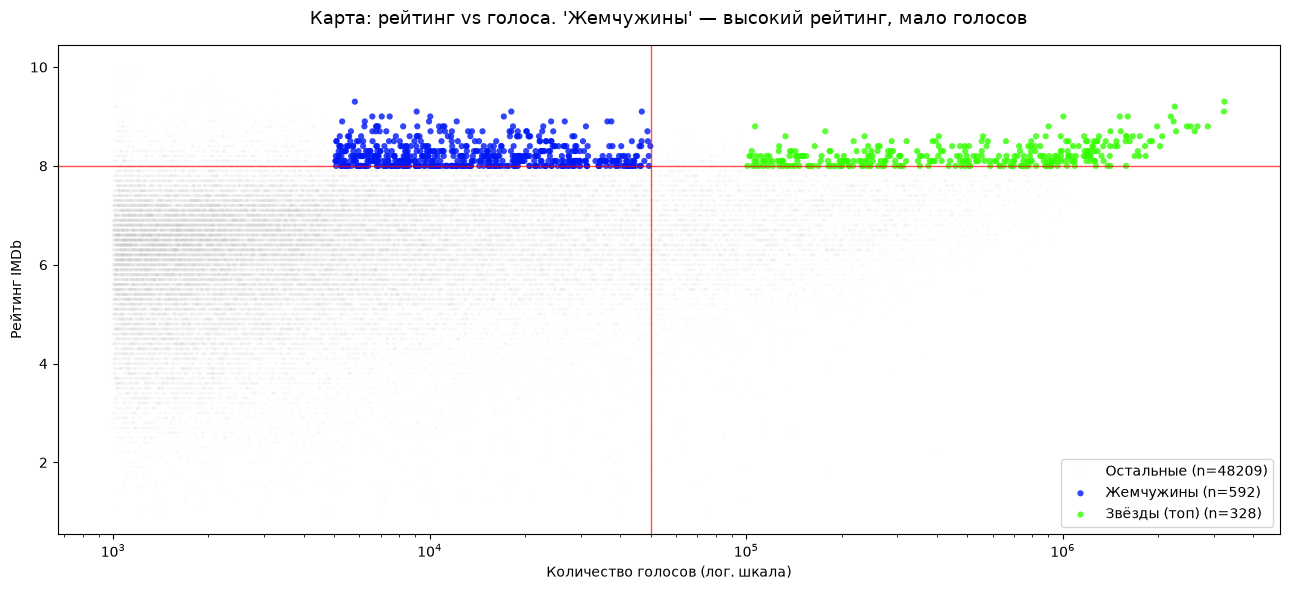

In [14]:
# Сравниваем три группы: жемчужины, мейнстрим, топ-100

fig, ax = plt.subplots(figsize=(13, 6))

colors_map = {
    'Остальные': "#CCCCCC",
    'Жемчужины': "#0018F5",
    'Звёзды (топ)': "#33FF00"
}

for cat, color in colors_map.items():
    sub = df_scatter[df_scatter['category'] == cat]
    alpha = 0.05 if cat == 'Остальные' else 0.8
    size = 5 if cat == 'Остальные' else 20
    ax.scatter(sub['numvotes'], sub['averagerating'],
               c=color, alpha=alpha, s=size, label=f"{cat} (n={len(sub)})",
               edgecolors='none')

ax.set_xscale('log')
ax.set_xlabel("Количество голосов (лог. шкала)")
ax.set_ylabel("Рейтинг IMDb")
ax.set_title("Карта: рейтинг vs голоса. 'Жемчужины' — высокий рейтинг, мало голосов",
             pad=15, fontsize=13)
ax.axhline(8.0, color='red', linestyle='-', alpha=0.7, linewidth=1)
ax.axvline(50000, color='red', linestyle='-', alpha=0.7, linewidth=1)
ax.legend(loc='lower right', fontsize=10)

plt.tight_layout()
plt.savefig(REPORTS_DIR / "04_hidden_gems_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

### Вывод

**«Скрытые жемчужины» — это фильмы с подтверждённым качеством, но не получившие массового признания.**

- «Скрытые жемчужины» — фильмы с рейтингом **8.0+** и **5K-50K голосов**. Их не видно в общих топах, но качество уже подтверждено достаточным числом зрителей (например, **Mission C1000**, **The Chaos Class**, **David Attenborough: A Life on Our Planet**).
- Среди жемчужин много **документальных фильмов, биографий и артхауса** (например, **O.J.: Made in America**, **Dominion**, **Mirror Game**). Это контент с лояльной, но небольшой аудиторией.
- **Карта рассеяния** наглядно показывает: с ростом голосов распределение рейтингов **сужается к среднему** (= 6.5-7.5). Остаться «в правом верхнем углу» (высокий рейтинг + много голосов) удаётся единицам.
- **«Мёртвая зона»** — фильмы с рейтингом < 6.0 и > 100K голосов. Их смотрят, но не любят.

**Импакт для бизнеса:** раздел «Рекомендации от редакции» на стриминге должен **искусственно продвигать жемчужины** — они не выиграют в алгоритмическом ранжировании, но дадут пользователю «вау-эффект» от просмотра.

## 4. Топ актеров и режиссеров

**Вопрос:** какие актеры и режиссеры дают «знак качества» — то есть фильмы с их участием стабильно высокорейтинговые?

**Зачем:** продюсер, выбирая актера, часто ориентируется на кассу. Хотим найти тех, кто **стабильно** даёт высокий IMDb-рейтинг.

### Топ 20 актеров

In [23]:
query_actors = """
SELECT 
    n.primaryname AS person,
    COUNT(DISTINCT b.tconst) AS movies_count,
    ROUND(AVG(r.averagerating), 2) AS avg_rating,
    ROUND(PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY r.averagerating)::numeric, 2) AS median_rating,
    ROUND(STDDEV(r.averagerating)::numeric, 2) AS std_rating
FROM title_basics b
JOIN title_ratings r ON b.tconst = r.tconst
JOIN title_principals p ON b.tconst = p.tconst
JOIN name_basics n ON p.nconst = n.nconst
WHERE 
    b.titletype = 'movie'
    AND r.numvotes >= 70000
    AND p.category IN ('actor', 'actress')
GROUP BY n.primaryname
HAVING COUNT(DISTINCT b.tconst) >= 10
ORDER BY median_rating DESC, movies_count DESC
LIMIT 20;
"""
df_actors = pd.read_sql(query_actors, engine)
df_actors

,person,movies_count,avg_rating,median_rating,std_rating
0,Joe Pesci,12,7.65,7.80,0.66
1,Michael Madsen,11,7.18,7.65,1.08
2,Mark Ruffalo,25,7.49,7.60,0.69
3,Al Pacino,23,7.30,7.60,1.22
4,Clint Eastwood,18,7.66,7.60,0.62
5,Emma Watson,15,7.19,7.60,0.90
6,Sebastian Stan,11,7.41,7.60,0.53
7,Leonardo DiCaprio,25,7.50,7.50,0.69
8,Jon Bernthal,18,7.33,7.50,0.62
9,Alan Tudyk,16,7.42,7.50,0.32


### Топ 20 режиссеров

In [24]:
query_directors = """
SELECT 
    n.primaryname AS person,
    COUNT(DISTINCT b.tconst) AS movies_count,
    ROUND(AVG(r.averagerating), 2) AS avg_rating,
    ROUND(PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY r.averagerating)::numeric, 2) AS median_rating,
    ROUND(STDDEV(r.averagerating)::numeric, 2) AS std_rating
FROM title_basics b
JOIN title_ratings r ON b.tconst = r.tconst
JOIN title_principals p ON b.tconst = p.tconst
JOIN name_basics n ON p.nconst = n.nconst
WHERE 
    b.titletype = 'movie'
    AND r.numvotes >= 70000
    AND p.category = 'director'
GROUP BY n.primaryname
HAVING COUNT(DISTINCT b.tconst) >= 5
ORDER BY median_rating DESC, movies_count DESC
LIMIT 20;
"""
df_directors = pd.read_sql(query_directors, engine)
df_directors

,person,movies_count,avg_rating,median_rating,std_rating
0,Christopher Nolan,13,8.18,8.40,0.59
1,Charles Chaplin,5,8.34,8.40,0.18
2,Billy Wilder,6,8.20,8.30,0.30
3,Sergio Leone,5,8.34,8.30,0.34
4,Akira Kurosawa,6,8.30,8.25,0.18
5,Stanley Kubrick,11,8.06,8.20,0.33
6,Hayao Miyazaki,11,7.95,8.00,0.36
7,Denis Villeneuve,8,7.91,8.00,0.50
8,Alfred Hitchcock,13,7.94,7.90,0.35
9,Quentin Tarantino,12,7.85,7.90,0.62


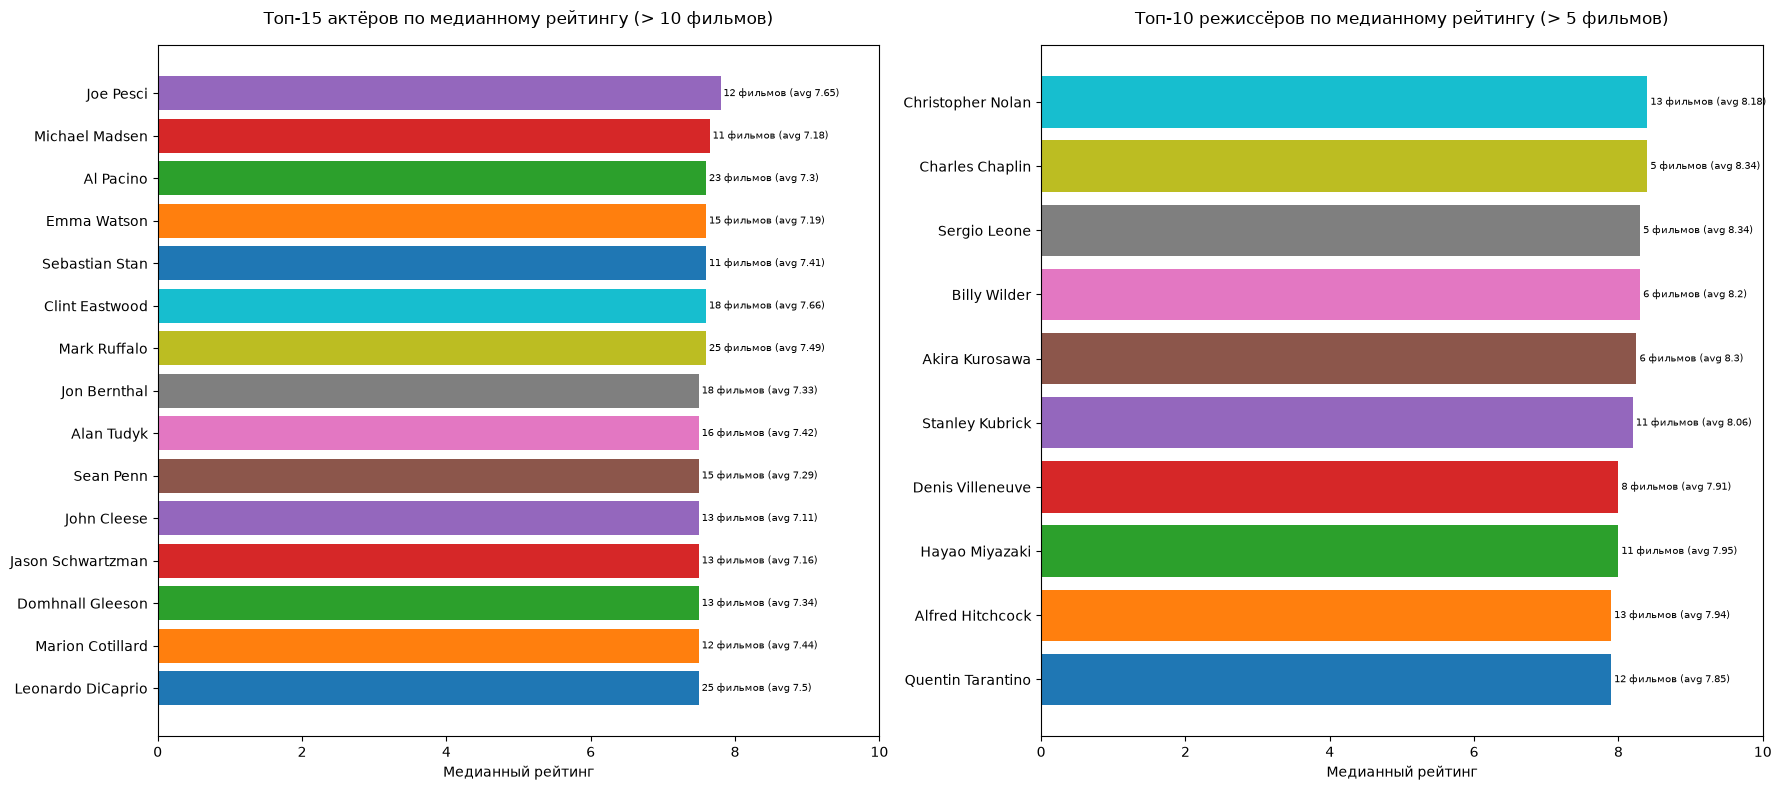

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# --- Актёры ---
top_actors = df_actors.head(15).sort_values('median_rating')
axes[0].barh(top_actors['person'], top_actors['median_rating'],
             color=sns.color_palette())
for bar, cnt, avg in zip(axes[0].patches,
                          top_actors['movies_count'],
                          top_actors['avg_rating']):
    axes[0].text(bar.get_width() * 1.005, bar.get_y() + bar.get_height()/2,
                 f"{cnt} фильмов (avg {avg})", va='center', fontsize=7)
axes[0].set_title("Топ-15 актёров по медианному рейтингу (> 10 фильмов)",
                  pad=15, fontsize=12)
axes[0].set_xlabel("Медианный рейтинг")
axes[0].set_xlim(0, 10)


# --- Режиссёры ---
top_directors = df_directors.head(10).sort_values('median_rating')
axes[1].barh(top_directors['person'], top_directors['median_rating'],
             color=sns.color_palette())
for bar, cnt, avg in zip(axes[1].patches,
                          top_directors['movies_count'],
                          top_directors['avg_rating']):
    axes[1].text(bar.get_width() * 1.005, bar.get_y() + bar.get_height()/2,
                 f"{cnt} фильмов (avg {avg})", va='center', fontsize=7)
axes[1].set_title("Топ-10 режиссёров по медианному рейтингу (> 5 фильмов)",
                  pad=15, fontsize=12)
axes[1].set_xlabel("Медианный рейтинг")
axes[1].set_xlim(0, 10)

plt.tight_layout()
plt.savefig(REPORTS_DIR / "05_top_actors_directors.png", dpi=150, bbox_inches="tight")
plt.show()

### Вывод

**Режиссёры и топовые актёры дают сопоставимый "знак качества", но разными путями.**

- **Топ актёров** (по медианному рейтингу) - это голливудские звёзды первой величины, работающие с сильными режиссёрами: **Joe Pesci** (медиана 7.80), **Michael Madsen** (7.65), **Mark Ruffalo** (7.60), **Al Pacino** (7.60), **Clint Eastwood** (7.60). Их медианный рейтинг - **7.5-7.8**.
- **Топ режиссёров** - это признанные авторы с устойчивым почерком: **Christopher Nolan** (медиана 8.40), **Charles Chaplin** (8.40), **Billy Wilder** (8.30), **Sergio Leone** (8.30), **Akira Kurosawa** (8.25). Их медианный рейтинг - **7.7-8.4**.
- **Разброс (std)** у топ-людей низкий: **0.2-1.2**. У топовых режиссёров (**Kubrick** 0.33, **Miyazaki** 0.36, **Hitchcock** 0.35, **Kurosawa** 0.18) разброс стабильно ниже 0.4 - это и есть "знак качества". У актёров разброс выше: **0.5-1.2**.
- **Ключевой инсайт:** медианный рейтинг у топ-режиссёров (**8.0-8.4**) заметно выше, чем у топ-актёров (**7.5-7.8**). Особенно это видно в верхней части рейтинга: у режиссёров **6 человек** с медианой выше 8.0, у актёров - **ни одного**. Это подтверждает гипотезу, что именно режиссёр является главным "автором" успеха фильма.

## Общий вывод по продвинутому анализу

Продвинутый анализ IMDb, выходящий за рамки базовых метрик, позволяет выявить нетривиальные закономерности, критически важные для принятия бизнес-решений в киноиндустрии и стриминге.

### 1. Качество против массовости
Анализ комбо-жанров показывает чёткий **трейд-офф**: массовые комбинации (**Comedy + Drama**, 6526 фильмов, avg 6.50) имеют рейтинг ниже среднего, в то время как нишевые (**Documentary + Biography**, сотни фильмов, avg > 7.2) - значительно выше. Это означает, что стратегия платформы должна зависеть от её бизнес-целей: привлечение широкой аудитории требует одних жанров, а удержание и создание "вау-эффекта" - других.

### 2. Голоса как индикатор доверия
Количество голосов - не просто мера популярности, но и **индикатор надёжности рейтинга**. Разброс оценок резко падает с ростом числа голосов (**std с 1.30 до 0.36**), а средний рейтинг растёт (**с 5.74 до 8.38**). Это доказывает, что для построения честных топов необходимо использовать **взвешенные рейтинги**, чтобы отсеять статистический шум от фильмов с малым числом оценок.

### 3. Существование "скрытых жемчужин"
На платформе существует значительный пласт фильмов (**~1.6%** от всех), которые имеют высокий рейтинг (**8.0+**), но не получили массового признания (**5K-50K голосов**). Эти фильмы, часто представленные документалистикой и биографиями, являются идеальными кандидатами для **редакционных подборок**, способных повысить удовлетворённость пользователей.

### 4. Режиссёр - главный "знак качества"
Анализ людей за камерой показывает, что режиссёры оказывают более сильное влияние на итоговое качество фильма, чем актёры. Медианный рейтинг топ-режиссёров (**8.0-8.4**) заметно выше, чем у топ-актёров (**7.5-7.8**), а разброс их оценок стабильно ниже (**0.2-0.6** против **0.5-1.2**). Среди топ-10 режиссёров - **6 человек** с медианой выше 8.0 (**Nolan, Chaplin, Wilder, Leone, Kurosawa, Kubrick**), среди топ-20 актёров таких **нет ни одного**. Это делает фигуру режиссёра ключевой при формировании контентных стратегий и рекомендательных систем.

### Итог
Проект демонстрирует, что переход от простого описания данных к многофакторному анализу позволяет выявить глубинные закономерности, лежащие в основе успеха фильмов, и сформулировать конкретные, обоснованные рекомендации для бизнеса.